# When, where, and how was temperature measured?

This notebook analyzes `data/alles.csv`, downloaded from the **Mobile Datalogger** data link on the [GreenCity resources page](https://hackathon.greencity.hn/resources). That page describes the Mobile Datalogger as a temperature/humidity sensor carried while walking, and links to the `Heat-Island-Summerschool 2026` Nextcloud folder.

**Provenance warning:** the CSV's `recording` values contain names such as `senseBox_bike_...`, and the file also has GPS and speed fields. Those labels do not prove that these rows came from the ATRAI bike API, but they do conflict with the resource page's description of a walking logger. This notebook treats the file as the downloaded `alles.csv` source and keeps it separate from both API collections until the data provider confirms the device and export process.

The goal is to describe the **actual coverage of the measurements** before interpreting the heat map.

**Important:** these are measurements from specific trips over three days, not a uniform sample of all of Heilbronn or an official climate time series. The charts describe what the sensor recorded and should not be interpreted as a controlled comparison between neighborhoods.


## How to interpret the timestamps

The `timestamp` column ends in `Z`, which indicates UTC. In September 2026, Heilbronn uses **CEST (UTC+2)**. The charts convert timestamps to the `Europe/Berlin` time zone while retaining the original UTC timestamp. The `recording` column helps distinguish actual capture periods: a file spanning several days does not mean the sensor measured continuously. The comparison cell at the end uses local clock time for one configurable date and half-open time window (`start <= time < end`).


In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 13})

DATA_PATH = Path.cwd() / "data" / "alles.csv"
if not DATA_PATH.exists():
    DATA_PATH = Path.cwd().parent / "data" / "alles.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find data/alles.csv. Open the notebook from the project folder "
        "or update DATA_PATH to the location of the CSV."
    )

print(f"File: {DATA_PATH.resolve()}")


File: C:\Users\marce\Documents\GitHub\Tree-Mendous\data\alles.csv


In [2]:
df = pd.read_csv(DATA_PATH)
required_columns = {
    "timestamp", "latitude", "longitude", "temperature",
    "humidity", "gps_speed", "recording",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

numeric_columns = ["latitude", "longitude", "temperature", "humidity", "gps_speed"]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["timestamp_utc"] = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")
df["timestamp_local"] = df["timestamp_utc"].dt.tz_convert("Europe/Berlin")
df["local_date"] = df["timestamp_local"].dt.date
df["local_hour"] = df["timestamp_local"].dt.hour

valid = df.dropna(subset=["timestamp_local", "latitude", "longitude", "temperature"]).copy()
valid = valid[
    valid["latitude"].between(-90, 90)
    & valid["longitude"].between(-180, 180)
]

print(f"Rows in CSV: {len(df):,}")
print(f"Rows valid for time, location, and temperature analysis: {len(valid):,}")
print(f"Distinct recordings: {df['recording'].nunique(dropna=True)}")
display(df.head())


Rows in CSV: 61,546
Rows valid for time, location, and temperature analysis: 61,546
Distinct recordings: 31


,timestamp,latitude,longitude,temperature,humidity,gps_speed,recording,timestamp_utc,timestamp_local,local_date,local_hour
0,2026-09-01T09:42:12.000Z,49.151947,9.215517,25.68,74.91,0.50,senseBox_bike_2026-09-01_11-42_standard_1.csv,2026-09-01 09:42:12+00:00,2026-09-01 11:42:12+02:00,2026-09-01,11
1,2026-09-01T09:42:13.000Z,49.151947,9.215514,25.68,75.12,0.34,senseBox_bike_2026-09-01_11-42_standard_1.csv,2026-09-01 09:42:13+00:00,2026-09-01 11:42:13+02:00,2026-09-01,11
2,2026-09-01T09:42:14.000Z,49.151958,9.215516,25.69,74.91,0.40,senseBox_bike_2026-09-01_11-42_standard_1.csv,2026-09-01 09:42:14+00:00,2026-09-01 11:42:14+02:00,2026-09-01,11
3,2026-09-01T09:42:15.000Z,49.151959,9.215539,25.69,73.72,0.34,senseBox_bike_2026-09-01_11-42_standard_1.csv,2026-09-01 09:42:15+00:00,2026-09-01 11:42:15+02:00,2026-09-01,11
4,2026-09-01T09:42:16.000Z,49.151956,9.215553,25.71,72.63,0.13,senseBox_bike_2026-09-01_11-42_standard_1.csv,2026-09-01 09:42:16+00:00,2026-09-01 11:42:16+02:00,2026-09-01,11


In [3]:
start_utc = valid["timestamp_utc"].min()
end_utc = valid["timestamp_utc"].max()
start_local = valid["timestamp_local"].min()
end_local = valid["timestamp_local"].max()

print(f"First reading: {start_local:%Y-%m-%d %H:%M:%S %Z} (UTC: {start_utc:%Y-%m-%d %H:%M:%S})")
print(f"Last reading:  {end_local:%Y-%m-%d %H:%M:%S %Z} (UTC: {end_utc:%Y-%m-%d %H:%M:%S})")
print(f"Window between first and last reading: {end_local - start_local}")
print("This window includes breaks; it does not imply continuous measurement.")

daily = (
    valid.groupby("local_date")
    .agg(
        readings=("temperature", "size"),
        recordings=("recording", "nunique"),
        mean_temperature_c=("temperature", "mean"),
        median_temperature_c=("temperature", "median"),
        min_temperature_c=("temperature", "min"),
        max_temperature_c=("temperature", "max"),
    )
)
daily.index.name = "Local date"
display(daily.round(2))


First reading: 2026-09-01 11:42:12 CEST (UTC: 2026-09-01 09:42:12)
Last reading:  2026-09-03 14:20:39 CEST (UTC: 2026-09-03 12:20:39)
Window between first and last reading: 2 days 02:38:27.728437
This window includes breaks; it does not imply continuous measurement.


,readings,recordings,mean_temperature_c,median_temperature_c,min_temperature_c,max_temperature_c
Local date,,,,,,
2026-09-01,13964,17,26.66,26.70,24.26,28.87
2026-09-02,43824,12,24.30,24.47,19.88,29.59
2026-09-03,3758,2,26.80,26.87,25.97,27.68


,start_local,end_local,readings,mean_temperature_c,median_interval_seconds,p95_interval_seconds,gaps_over_60_seconds,duration_minutes
recording,,,,,,,,
senseBox_bike_2026-09-01_11-42_standard_1.csv,2026-09-01 11:42:12.000+02:00,2026-09-01 11:55:23.003000+02:00,768,26.68,1.0,1.00000,0,13.2
senseBox_bike_2026-09-01_11-44_standard_2 3.csv,2026-09-01 11:44:28.999+02:00,2026-09-01 11:55:22.750347+02:00,655,25.76,1.0,1.00000,0,10.9
senseBox_bike_2026-09-01_11-44_standard_2 2.csv,2026-09-01 11:44:40.697+02:00,2026-09-01 11:55:22.232975+02:00,571,26.21,1.0,1.00000,0,10.7
senseBox_bike_2026-09-01_11-44_standard_17.csv,2026-09-01 11:44:40.998+02:00,2026-09-01 11:55:22.467757+02:00,548,25.47,1.0,1.00000,0,10.7
senseBox_bike_2026-09-01_11-44_standard_2.csv,2026-09-01 11:44:51.999+02:00,2026-09-01 11:55:18.937764+02:00,543,26.40,1.0,1.00000,0,10.4
senseBox_bike_2026-09-01_11-45_standard_2 2.csv,2026-09-01 11:45:14.548+02:00,2026-09-01 11:55:22.192343+02:00,458,26.51,1.0,1.41400,0,10.1
senseBox_bike_2026-09-01_11-45_standard_2.csv,2026-09-01 11:45:21.130+02:00,2026-09-01 11:54:06.002000+02:00,510,25.55,1.0,1.00000,0,8.7
senseBox_bike_2026-09-01_11-45_standard_2 3.csv,2026-09-01 11:45:43.996+02:00,2026-09-01 11:55:22.992000+02:00,576,25.54,1.0,1.00000,0,9.6
senseBox_bike_2026-09-01_13-31_standard_1.csv,2026-09-01 13:31:36.231+02:00,2026-09-01 13:52:38.943000+02:00,1206,26.07,1.0,1.00000,0,21.0


Recording durations (minutes):


,duration_minutes
count,31.0
mean,36.0
std,32.2
min,6.3
25%,10.8
50%,20.1
75%,53.0
max,121.6


Intervals are calculated within each recording; a gap over 60 seconds indicates a pause, not necessarily a sensor failure.


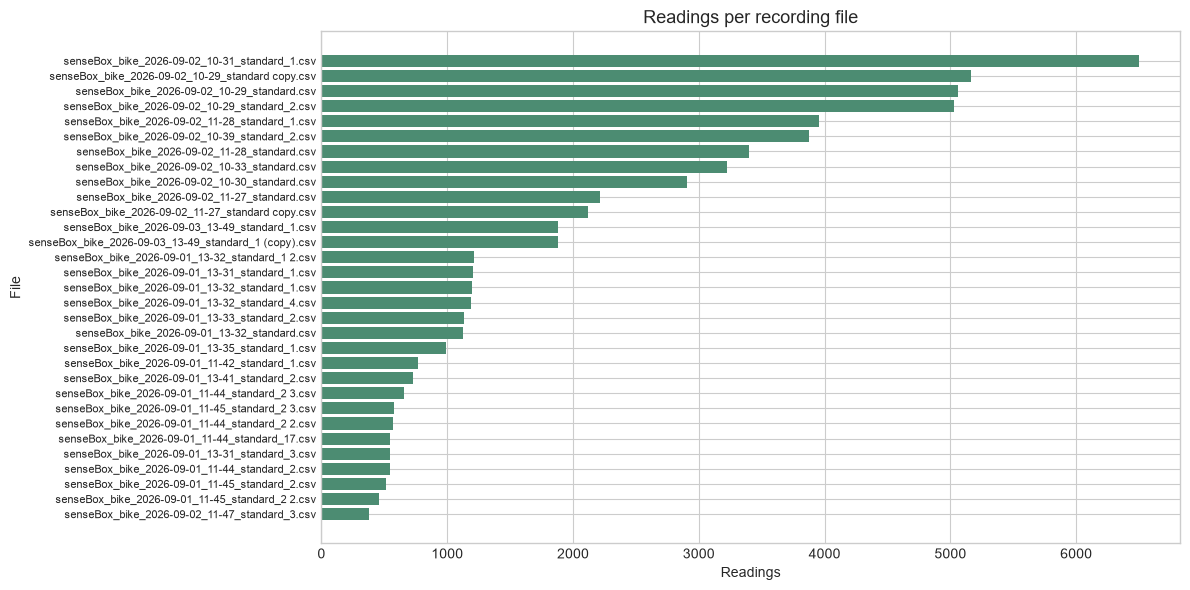

In [4]:
recording_rows = valid.dropna(subset=["recording"]).sort_values("timestamp_local").copy()
recording_rows["interval_seconds"] = (
    recording_rows.groupby("recording")["timestamp_local"]
    .diff().dt.total_seconds()
)

recordings = recording_rows.groupby("recording").agg(
    start_local=("timestamp_local", "min"),
    end_local=("timestamp_local", "max"),
    readings=("timestamp_local", "size"),
    mean_temperature_c=("temperature", "mean"),
    median_interval_seconds=("interval_seconds", "median"),
    p95_interval_seconds=("interval_seconds", lambda values: values.quantile(0.95)),
    gaps_over_60_seconds=("interval_seconds", lambda values: int((values > 60).sum())),
).sort_values("start_local")
recordings["duration_minutes"] = (
    recordings["end_local"] - recordings["start_local"]
).dt.total_seconds() / 60

display(recordings.round({"duration_minutes": 1, "mean_temperature_c": 2}))
print("Recording durations (minutes):")
display(recordings["duration_minutes"].describe().round(1).to_frame())
print("Intervals are calculated within each recording; a gap over 60 seconds indicates a pause, not necessarily a sensor failure.")

fig, ax = plt.subplots(figsize=(12, 6))
ordered = recordings.sort_values("readings")
ax.barh(ordered.index, ordered["readings"], color="#4c8c72")
ax.set(title="Readings per recording file", xlabel="Readings", ylabel="File")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()


In [5]:
quality = pd.Series(
    {
        "Original rows": len(df),
        "Unparseable timestamps": int(df["timestamp_utc"].isna().sum()),
        "Missing/non-numeric temperatures": int(df["temperature"].isna().sum()),
        "Missing/non-numeric coordinates": int(df[["latitude", "longitude"]].isna().any(axis=1).sum()),
        "Completely duplicated rows": int(df.duplicated().sum()),
        "Duplicated timestamps": int(df["timestamp_utc"].duplicated().sum()),
        "Rows without a recording name": int(df["recording"].isna().sum()),
    },
    name="Value",
)
display(quality.to_frame())

display(
    valid[["temperature", "humidity", "gps_speed", "latitude", "longitude"]]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    .T.round(3)
)
print("Note: confirm the units and calibration of humidity and gps_speed against the sensor documentation.")


,Value
Original rows,61546
Unparseable timestamps,0
Missing/non-numeric temperatures,0
Missing/non-numeric coordinates,0
Completely duplicated rows,0
Duplicated timestamps,7485
Rows without a recording name,0


,count,mean,std,min,5%,25%,50%,75%,95%,max
temperature,61546.0,24.989,1.969,19.880,21.190,23.730,25.250,26.550,27.600,29.590
humidity,61543.0,50.561,6.456,38.590,41.040,45.380,50.480,54.960,62.270,75.120
gps_speed,61546.0,0.781,0.490,0.000,0.010,0.210,0.960,1.180,1.360,2.960
latitude,61546.0,49.151,0.005,49.142,49.143,49.147,49.151,49.155,49.162,49.164
longitude,61546.0,9.216,0.007,9.205,9.208,9.212,9.215,9.218,9.233,9.235


Note: confirm the units and calibration of humidity and gps_speed against the sensor documentation.


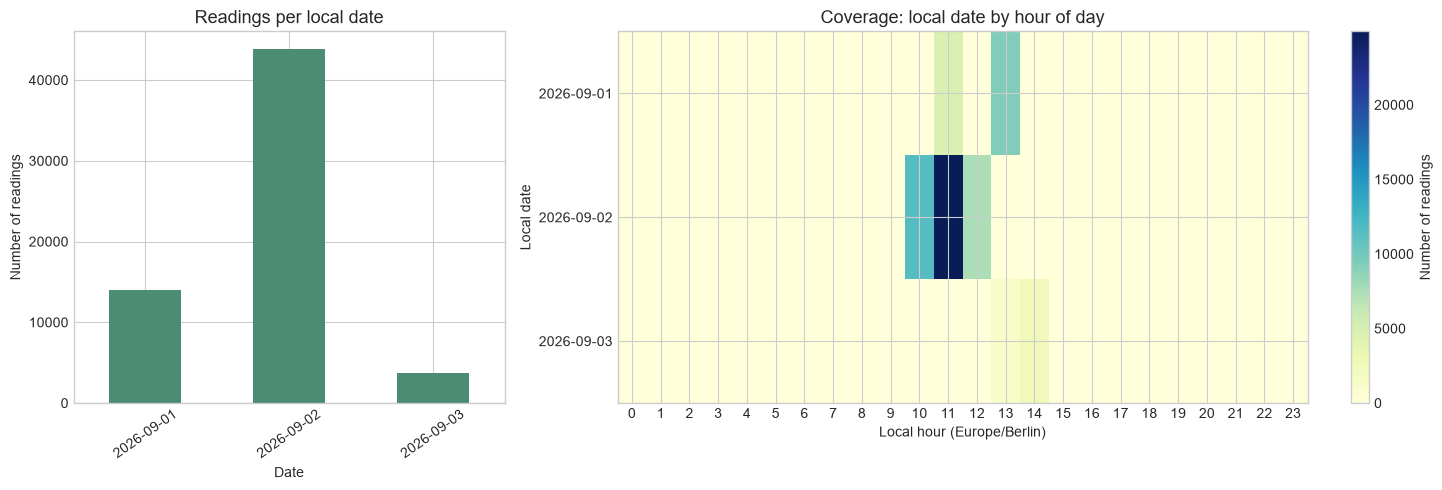

,readings,days_with_data
Local hour,,
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0


In [6]:
counts_by_day_hour = valid.pivot_table(
    index="local_date", columns="local_hour", values="temperature",
    aggfunc="count", fill_value=0,
).reindex(columns=range(24), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2]})
daily["readings"].plot(kind="bar", ax=axes[0], color="#4c8c72")
axes[0].set(title="Readings per local date", xlabel="Date", ylabel="Number of readings")
axes[0].tick_params(axis="x", rotation=35)

image = axes[1].imshow(counts_by_day_hour.values, aspect="auto", cmap="YlGnBu")
axes[1].set(
    title="Coverage: local date by hour of day",
    xlabel="Local hour (Europe/Berlin)",
    ylabel="Local date",
    xticks=range(24),
    yticks=range(len(counts_by_day_hour.index)),
    yticklabels=[str(day) for day in counts_by_day_hour.index],
)
fig.colorbar(image, ax=axes[1], label="Number of readings")
fig.tight_layout()
plt.show()

hourly_coverage = pd.DataFrame(
    {
        "readings": valid.groupby("local_hour").size(),
        "days_with_data": valid.groupby("local_hour")["local_date"].nunique(),
    }
).reindex(range(24), fill_value=0)
hourly_coverage.index.name = "Local hour"
display(hourly_coverage)


## Measurement times on September 2

The table below groups valid readings by **local clock hour in Heilbronn**. It shows the first and last observed measurement in each hour, the number of readings, and the number of distinct recording files. The first/last times are observed boundaries, not evidence that measurements were continuous throughout the interval.


In [7]:
september_2 = valid.loc[
    valid["local_date"] == pd.Timestamp("2026-09-02").date()
].copy()
if september_2.empty:
    raise ValueError("No valid measurements were found for September 2, 2026.")

september_2_by_hour = september_2.groupby("local_hour").agg(
    first_measurement=("timestamp_local", "min"),
    last_measurement=("timestamp_local", "max"),
    readings=("timestamp_local", "size"),
    recording_files=("recording", "nunique"),
)
september_2_by_hour["first_measurement"] = september_2_by_hour["first_measurement"].dt.strftime("%H:%M:%S")
september_2_by_hour["last_measurement"] = september_2_by_hour["last_measurement"].dt.strftime("%H:%M:%S")
september_2_by_hour.index = [f"{hour:02d}:00-{hour:02d}:59" for hour in september_2_by_hour.index]
september_2_by_hour.index.name = "Local clock hour (CEST)"
september_2_by_hour = september_2_by_hour.rename(
    columns={
        "first_measurement": "First measurement",
        "last_measurement": "Last measurement",
        "readings": "Readings",
        "recording_files": "Recording files",
    }
)
display(september_2_by_hour)
print(
    "Overall on September 2: "
    f"{september_2['timestamp_local'].min():%H:%M:%S} to "
    f"{september_2['timestamp_local'].max():%H:%M:%S} CEST."
)


,First measurement,Last measurement,Readings,Recording files
Local clock hour (CEST),,,,
10:00-10:59,10:29:08,10:59:59,11433,7
11:00-11:59,11:00:00,11:59:59,24915,12
12:00-12:59,12:00:00,12:59:53,7414,6
13:00-13:59,13:00:08,13:07:39,62,1


Overall on September 2: 10:29:08 to 13:07:39 CEST.


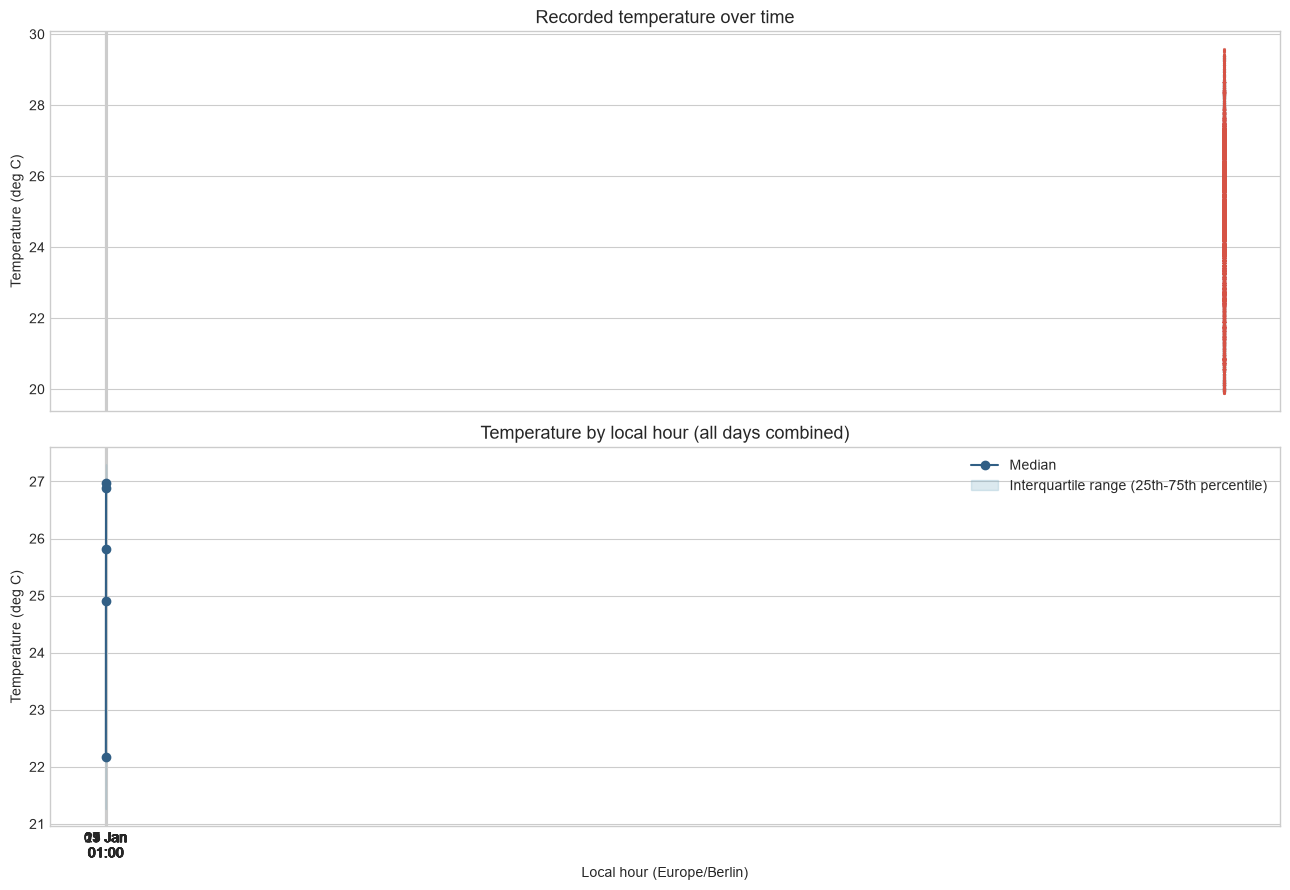

The distribution by hour depends on when and where the bicycle traveled.


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

axes[0].scatter(
    valid["timestamp_local"], valid["temperature"],
    s=5, alpha=0.28, color="#d65345", linewidths=0,
)
axes[0].set(title="Recorded temperature over time", ylabel="Temperature (deg C)")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M", tz=valid["timestamp_local"].dt.tz))

hourly_temperature = valid.groupby("local_hour")["temperature"]
median_temperature = hourly_temperature.median()
p25_temperature = hourly_temperature.quantile(0.25)
p75_temperature = hourly_temperature.quantile(0.75)
hours = median_temperature.index
axes[1].plot(hours, median_temperature, marker="o", color="#315f85", label="Median")
axes[1].fill_between(
    hours, p25_temperature, p75_temperature,
    color="#72a9c1", alpha=0.25, label="Interquartile range (25th-75th percentile)",
)
axes[1].set(
    title="Temperature by local hour (all days combined)",
    xlabel="Local hour (Europe/Berlin)", ylabel="Temperature (deg C)", xticks=range(0, 24, 2),
)
axes[1].legend()
fig.tight_layout()
plt.show()

print("The distribution by hour depends on when and where the bicycle traveled.")


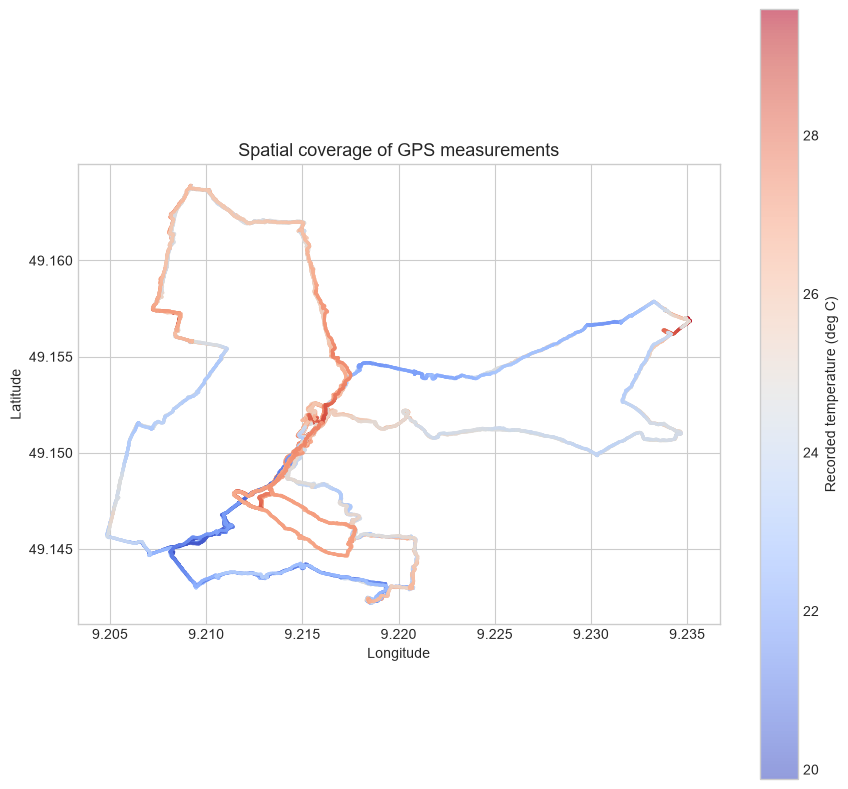

Each point is one reading. Denser sections may result from repeated passes, speed, or recording duration.


In [9]:
fig, ax = plt.subplots(figsize=(9, 8))
points = ax.scatter(
    valid["longitude"], valid["latitude"], c=valid["temperature"],
    s=5, alpha=0.55, cmap="coolwarm", vmin=valid["temperature"].min(),
    vmax=valid["temperature"].max(), linewidths=0,
)
fig.colorbar(points, ax=ax, label="Recorded temperature (deg C)")
ax.set(
    title="Spatial coverage of GPS measurements",
    xlabel="Longitude", ylabel="Latitude", aspect="equal",
)
plt.tight_layout()
plt.show()

print("Each point is one reading. Denser sections may result from repeated passes, speed, or recording duration.")


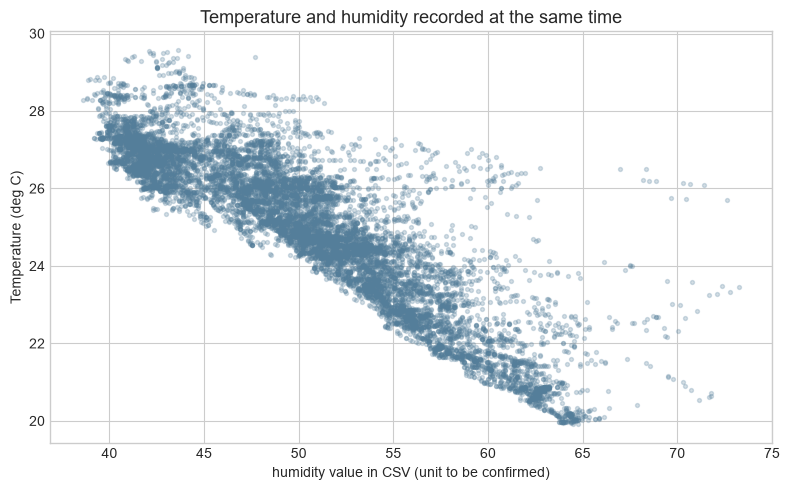

Descriptive relationship only: this does not isolate time, location, sun exposure, or calibration effects.


In [10]:
relation = valid.dropna(subset=["humidity", "temperature"])
if len(relation) > 12_000:
    relation = relation.sample(12_000, random_state=42)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(relation["humidity"], relation["temperature"], s=8, alpha=0.25, color="#547e9a")
ax.set(
    title="Temperature and humidity recorded at the same time",
    xlabel="humidity value in CSV (unit to be confirmed)",
    ylabel="Temperature (deg C)",
)
plt.tight_layout()
plt.show()
print("Descriptive relationship only: this does not isolate time, location, sun exposure, or calibration effects.")


## A consistent date and time window

Use this cell to summarize just one local day and a selected time window. The default (September 2, 10:00–14:00 CEST) covers the time span in this file and can be copied to the API notebooks. Matching dates and clock hours is not enough to prove the devices measured the same air mass; check device location, timestamp conventions, and calibration before comparing temperatures.


In [ ]:
TARGET_DATE = "2026-09-02"
START_LOCAL = "10:00"
END_LOCAL = "14:00"  # exclusive

window_start = pd.Timestamp(f"{TARGET_DATE} {START_LOCAL}").tz_localize("Europe/Berlin")
window_end = pd.Timestamp(f"{TARGET_DATE} {END_LOCAL}").tz_localize("Europe/Berlin")
if window_end <= window_start:
    raise ValueError("END_LOCAL must be later than START_LOCAL on the selected date.")

comparison_window = valid.loc[
    (valid["timestamp_local"] >= window_start)
    & (valid["timestamp_local"] < window_end)
].copy()
if comparison_window.empty:
    raise ValueError("No valid mobile CSV measurements fall within this date/time window.")

comparison_window["local_hour"] = comparison_window["timestamp_local"].dt.hour
mobile_hourly = comparison_window.groupby("local_hour").agg(
    first_reading=("timestamp_local", "min"),
    last_reading=("timestamp_local", "max"),
    readings=("temperature", "count"),
    mean_temperature_c=("temperature", "mean"),
    median_temperature_c=("temperature", "median"),
)
mobile_hourly["first_reading"] = mobile_hourly["first_reading"].dt.strftime("%H:%M:%S")
mobile_hourly["last_reading"] = mobile_hourly["last_reading"].dt.strftime("%H:%M:%S")
mobile_hourly.index.name = "Local hour (Europe/Berlin)"
display(mobile_hourly.round(2))
print(f"Window: {window_start} <= local time < {window_end}")


## Criteria for interpreting the charts

- **Local time:** converting UTC to `Europe/Berlin` avoids interpreting, for example, 09:42Z as 09:42 in Heilbronn.
- **Time coverage:** the overall range from the first to last reading includes interruptions. Use the recording table and date-hour matrix to find when samples were actually collected.
- **Uneven frequency:** many readings in an hour or place do not mean it was hotter there; they may reflect more travel time, repeated passes, or pauses.
- **Repeated timestamps:** different rows can have the same timestamp without being completely duplicated rows. Check the recording files before removing or treating these observations as errors.
- **Comparisons between hours/days:** routes and conditions may differ. Differences do not isolate the effect of time and are not a controlled weather trend.
- **Heat map:** values between routes are visual interpolation; a lack of readings outside the routes does not mean a lack of heat.
- **Data quality and provenance:** check calibration, units, sensor location, and original recording names before using the results as official evidence.
